# 世界13都市の天気で比べる気候区分

**メンバー**
- **三橋龍之輔　原田琉太　林崎仁**

---

## このNotebookでできること

気候区分の違う世界13都市（各気候の代表都市）について、今日から7日間の「平均気温」と「平均降水量」を自動で取得し、表とグラフで比べることができる。
（気候区分が、実際の1週間の天気にどう表れるかを、データで確かめる）

| 出力 | 内容 | 分かること |
|---|---|---|
| 都市ごとの7日間まとめ | 最高・最低・平均気温、日ごとの降水量 | 各都市の1週間の天気の詳細 |
| 比較表（降水量の多い順） | 気候・都市・平均気温・平均降水量 | 雨の多い都市／少ない都市のランキング |
| 棒グラフ＋点の複合グラフ | 棒＝平均降水量、点＝平均気温 | 降水量と気温を同時に見比べる |
| 散布図（横：気温、縦：降水量） | 点線の基準線で4つの領域に色分け | 「暑くて雨が多い」「寒くて乾燥」などのタイプ分け |

## 対象の13都市

熱帯雨林（シンガポール）／熱帯モンスーン（ジャカルタ）／サバナ（バンコク）／砂漠（カイロ）／ステップ・高温（ニアメ）／ステップ・低温（ウランバートル）／温暖湿潤（東京）／西岸海洋性（ロンドン）／地中海性（アテネ）／温帯冬季少雨（ハノイ）／冷帯湿潤（モスクワ）／冷帯冬季少雨（平壌）／ツンドラ（ヌーク）

## 天気データの出典

- **Open-Meteo（Weather Forecast API）**：https://open-meteo.com/en/docs
  - 取得URL：`https://api.open-meteo.com/v1/forecast`
  - 使用した項目：`temperature_2m_max` / `temperature_2m_min`（日ごとの最高・最低気温）、`temperature_2m`（1時間ごとの気温）、`precipitation_sum`（日ごとの降水量）
- 授業の資料：Week 07 天気コード集（参考）
  https://yohman.github.io/26-2-Programming/weeks/week-07/weather-code.html

※ 取得したデータは予報値のため、実行する日によって結果が変わる。（このNotebookの結果は **2026-11-18** に取得）

In [1]:
# ① 取得する場所と期間を設定する（柏市の例）

# 緯度
lat = 35.86224

# 経度
lon = 139.97733

# 過去何日分を含めるか
past_days = 1

# 今日を含む予報の日数
forecast_days = 3

# 取得する場所の現地時間を使う
timezone = "auto"

# 欲しい天気の項目を、カンマ区切りの文字列で指定する
daily_fields = (
    "temperature_2m_max,temperature_2m_min,"
    "precipitation_probability_max,rain_sum,showers_sum"
)

# 通信を待つ最大秒数
timeout = 10

In [2]:
# 通信とJSONの読み取りに使う標準ライブラリ
import json
from urllib.request import urlopen
from urllib.parse import urlencode

# ② 設定した変数をパラメータに渡し、URLを作る
url = "https://api.open-meteo.com/v1/forecast?" + urlencode({
    "latitude": lat, "longitude": lon,
    "daily": daily_fields,
    "past_days": past_days, "forecast_days": forecast_days,
    "timezone": timezone
})

# ③ APIから取得したJSONを、Pythonの辞書に変換する
with urlopen(url, timeout=timeout) as response:
    weather = json.load(response)

# ④ 日別データを表示する（セルの最後の値はprint不要）
weather["daily"]

{'time': ['2026-11-17', '2026-11-18', '2026-11-19', '2026-11-20'],
 'temperature_2m_max': [13.7, 19.3, 18.1, 15.6],
 'temperature_2m_min': [9.2, 9.2, 9.2, 7.7],
 'precipitation_probability_max': [100, 100, 12, 0],
 'rain_sum': [24.4, 26.1, 0.0, 0.0],
 'showers_sum': [0.0, 0.0, 0.0, 0.0]}

In [3]:
# 通信とJSONの読み取りに使う標準ライブラリ
import json
from urllib.request import urlopen
from urllib.parse import urlencode

# ① 都市ごとの設定（名前: (緯度, 経度, 気候)）
cities = {
    "シンガポール": (1.3521, 103.8198, "熱帯雨林"),
    "バンコク":     (13.7563, 100.5018, "サバナ"),
    "カイロ":       (30.0444, 31.2357, "砂漠"),
    "ローマ":       (41.9028, 12.4964, "地中海性"),
    "東京":         (35.6895, 139.6917, "温暖湿潤"),
    "ロンドン":     (51.5074, -0.1278, "西岸海洋性"),
    "モスクワ":     (55.7558, 37.6173, "冷帯"),
    "レイキャビク": (64.1466, -21.9426, "亜寒帯"),
}

# 今日を含む7日間（過去日は含めない）
past_days = 0
forecast_days = 7

# 日ごとの平均気温と合計降水量（雨・雪を含む）を取得
daily_fields = "temperature_2m_mean,precipitation_sum"

# ② 都市ごとにAPIを呼び出し、結果を辞書にためる
results = {}

for name, (lat, lon, climate) in cities.items():
    url = "https://api.open-meteo.com/v1/forecast?" + urlencode({
        "latitude": lat, "longitude": lon,
        "daily": daily_fields,
        "past_days": past_days, "forecast_days": forecast_days,
        "timezone": "auto"
    })
    with urlopen(url, timeout=10) as response:
        weather = json.load(response)

    temps = weather["daily"]["temperature_2m_mean"]   # 日ごとの平均気温（°C）
    rains = weather["daily"]["precipitation_sum"]     # 日ごとの降水量（mm）

    results[name] = {
        "climate": climate,
        "avg_temp": sum(temps) / len(temps),          # 7日間の平均気温
        "total_rain": sum(rains),                     # 7日間の合計降水量
        "avg_rain": sum(rains) / len(rains),          # 1日あたりの平均降水量
    }

# ③ 結果を表示する
print(f"{'都市':<8}{'気候':<8}{'平均気温(°C)':>12}{'合計降水(mm)':>14}{'日平均降水(mm)':>16}")
for name, r in results.items():
    print(f"{name:<8}{r['climate']:<8}{r['avg_temp']:>12.1f}{r['total_rain']:>14.1f}{r['avg_rain']:>16.1f}")

都市      気候          平均気温(°C)      合計降水(mm)       日平均降水(mm)
シンガポール  熱帯雨林            25.9         124.6            17.8
バンコク    サバナ             30.6           3.2             0.5
カイロ     砂漠              20.5           0.0             0.0
ローマ     地中海性            14.9          18.4             2.6
東京      温暖湿潤            10.5          26.9             3.8
ロンドン    西岸海洋性            8.4          22.1             3.2
モスクワ    冷帯               1.5          14.1             2.0
レイキャビク  亜寒帯              2.6          30.3             4.3


In [4]:
import json
from urllib.request import urlopen
from urllib.parse import urlencode

# 気候区分と代表都市の座標
climate_cities = {
    "熱帯雨林": ("シンガポール", 1.3521, 103.8198),
    "熱帯モンスーン": ("ジャカルタ", -6.2088, 106.8456),
    "サバナ": ("バンコク", 13.7563, 100.5018),
    "砂漠": ("カイロ", 30.0444, 31.2357),
    "ステップ（高温）": ("ニアメ", 13.5137, 2.1098),
    "ステップ（低温）": ("ウランバートル", 47.9184, 106.9177),
    "温暖湿潤": ("東京", 35.6762, 139.6503),
    "西岸海洋性": ("ロンドン", 51.5074, -0.1278),
    "地中海性": ("アテネ", 37.9838, 23.7275),
    "温帯冬季少雨": ("ハノイ", 21.0285, 105.8542),
    "冷帯湿潤": ("モスクワ", 55.7558, 37.6173),
    "冷帯冬季少雨": ("平壌", 39.0339, 125.7543),
    "ツンドラ": ("ヌーク", 64.1814, -51.6942)
}

# 全都市の比較結果を保存するリスト
results = []

# 13都市を順番に処理
for climate, (city, latitude, longitude) in climate_cities.items():

    print("=" * 55)
    print("気候:", climate, "/ 都市:", city)

    # APIに渡す条件
    parameters = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "hourly": "temperature_2m",
        "forecast_days": 7,
        "timezone": "auto"
    }

    url = "https://api.open-meteo.com/v1/forecast?" + urlencode(parameters)

    try:
        # 天気データを取得
        with urlopen(url, timeout=20) as response:
            weather = json.load(response)

        daily = weather["daily"]

        dates = daily["time"]
        max_temps = daily["temperature_2m_max"]
        min_temps = daily["temperature_2m_min"]
        rainfall = daily["precipitation_sum"]

        # 1時間ごとの気温から7日間の平均を計算
        hourly_temps = [
            t for t in weather["hourly"]["temperature_2m"]
            if t is not None
        ]

        # 欠損値を除く
        valid_max = [t for t in max_temps if t is not None]
        valid_min = [t for t in min_temps if t is not None]
        valid_rain = [r for r in rainfall if r is not None]

        if (not valid_max or not valid_min
                or not valid_rain or not hourly_temps):
            print("有効なデータが不足しています")
            continue

        # 7日間のまとめ
        highest_temp = max(valid_max)
        lowest_temp = min(valid_min)
        average_temp = sum(hourly_temps) / len(hourly_temps)

        highest_rain = max(valid_rain)
        lowest_rain = min(valid_rain)
        average_rain = sum(valid_rain) / len(valid_rain)

        print()
        print("【7日間のまとめ】")
        print(f"最高気温: {highest_temp:.1f} ℃")
        print(f"最低気温: {lowest_temp:.1f} ℃")
        print(f"平均気温: {average_temp:.1f} ℃")
        print(f"最高降水量: {highest_rain:.1f} mm/日")
        print(f"最低降水量: {lowest_rain:.1f} mm/日")
        print(f"平均降水量: {average_rain:.1f} mm/日")

        # 7日間の日別データ
        print()
        print("【日別データ】")
        print("日付         最高℃    最低℃    降水量mm")

        for i in range(len(dates)):
            hi = max_temps[i]
            lo = min_temps[i]
            rain = rainfall[i]

            if hi is None or lo is None or rain is None:
                print(dates[i], "データなし")
                continue

            print(f"{dates[i]}   {hi:5.1f}   {lo:5.1f}   {rain:7.1f}")

        # 比較用に結果を保存
        results.append({
            "気候": climate,
            "都市": city,
            "平均気温": average_temp,
            "平均降水量": average_rain
        })

    except Exception as error:
        print("取得エラー:", error)

# 全都市の結果を比較
print()
print("=" * 55)
print("【全都市の7日間平均比較】")

for result in results:
    print(
        f"{result['気候']} / {result['都市']}: "
        f"平均気温 {result['平均気温']:.1f}℃ / "
        f"平均降水量 {result['平均降水量']:.1f}mm/日"
    )

print()
print(f"取得成功: {len(results)} / {len(climate_cities)} 都市")

気候: 熱帯雨林 / 都市: シンガポール

【7日間のまとめ】
最高気温: 33.0 ℃
最低気温: 23.1 ℃
平均気温: 25.9 ℃
最高降水量: 28.8 mm/日
最低降水量: 8.9 mm/日
平均降水量: 17.8 mm/日

【日別データ】
日付         最高℃    最低℃    降水量mm
2026-11-18    33.0    23.3      24.5
2026-11-19    29.9    23.4      13.3
2026-11-20    30.9    24.1      11.8
2026-11-21    31.5    23.4       8.9
2026-11-22    31.7    23.3      27.1
2026-11-23    32.0    23.2      10.2
2026-11-24    31.7    23.1      28.8
気候: 熱帯モンスーン / 都市: ジャカルタ

【7日間のまとめ】
最高気温: 33.7 ℃
最低気温: 24.1 ℃
平均気温: 27.3 ℃
最高降水量: 21.4 mm/日
最低降水量: 2.9 mm/日
平均降水量: 9.8 mm/日

【日別データ】
日付         最高℃    最低℃    降水量mm
2026-11-18    33.7    25.0      11.5
2026-11-19    30.8    24.1      21.4
2026-11-20    31.5    24.7      10.3
2026-11-21    30.6    24.6       2.9
2026-11-22    31.6    25.0       7.9
2026-11-23    31.4    24.7       8.5
2026-11-24    30.5    24.4       6.2
気候: サバナ / 都市: バンコク

【7日間のまとめ】
最高気温: 36.3 ℃
最低気温: 25.4 ℃
平均気温: 30.6 ℃
最高降水量: 1.2 mm/日
最低降水量: 0.0 mm/日
平均降水量: 0.5 mm/日

【日別データ】
日付         最高℃    最低℃    降水量mm


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

# ① 表にまとめる（平均降水量の多い順）
df = pd.DataFrame(results)
df = df.sort_values("平均降水量", ascending=False).reset_index(drop=True)
df["平均気温"] = df["平均気温"].round(1)
df["平均降水量"] = df["平均降水量"].round(1)
df = df.rename(columns={"平均気温": "平均気温(℃)", "平均降水量": "平均降水量(mm/日)"})
df = df[["気候", "都市", "平均気温(℃)", "平均降水量(mm/日)"]]
df.index = df.index + 1          # 行番号を1位, 2位, ... にする
df.index.name = "順位"

display(df)   # 通常のPythonファイルなら print(df.to_string())

# ② 日本語フォントの設定：環境にあるものを自動で選ぶ
candidates = ["Yu Gothic", "Meiryo", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "TakaoGothic"]
installed = {f.name for f in font_manager.fontManager.ttflist}
found = [f for f in candidates if f in installed]
if found:
    plt.rcParams["font.family"] = found[0]
else:
    print("日本語フォントが見つかりません。")
plt.rcParams["axes.unicode_minus"] = False

# ③ 棒グラフ（平均降水量）＋ 点（平均気温）の複合グラフ
fig, ax1 = plt.subplots(figsize=(14, 6))

# 棒グラフ：平均降水量（左軸）。表と同じ順（多い順）に並ぶ
bars = ax1.bar(df["都市"], df["平均降水量(mm/日)"], color="#6aa9e9", label="平均降水量（mm/日）")
ax1.set_ylabel("平均降水量（mm/日）", color="#2b6cb0")
ax1.tick_params(axis="y", labelcolor="#2b6cb0")
ax1.bar_label(bars, fmt="%.1f", fontsize=8)

# 平均気温（右軸）：線でつながず、少し大きめの点だけにする
ax2 = ax1.twinx()
dots, = ax2.plot(df["都市"], df["平均気温(℃)"], linestyle="none",
                 marker="o", markersize=10, color="#e0533d", markeredgecolor="white",
                 label="平均気温（℃）")
ax2.set_ylabel("平均気温（℃）", color="#e0533d")
ax2.tick_params(axis="y", labelcolor="#e0533d")
for x, y in zip(df["都市"], df["平均気温(℃)"]):
    ax2.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 10),
                 ha="center", fontsize=8, color="#e0533d")

# X軸に都市名と気候を併記
ax1.set_xticks(range(len(df)))
ax1.set_xticklabels([f"{c}\n{k}" for c, k in zip(df["都市"], df["気候"])], fontsize=8)

# 凡例をひとつにまとめる
ax1.legend([bars, dots], [bars.get_label(), dots.get_label()], loc="upper right")

ax1.set_title("今日から7日間の平均降水量が多い順：平均降水量と平均気温")
plt.tight_layout()
plt.savefig("weather_summary.png", dpi=150)
plt.show()
plt.show()

ImportError: DLL load failed while importing indexers: アプリケーション制御ポリシーによってこのファイルがブロックされました。

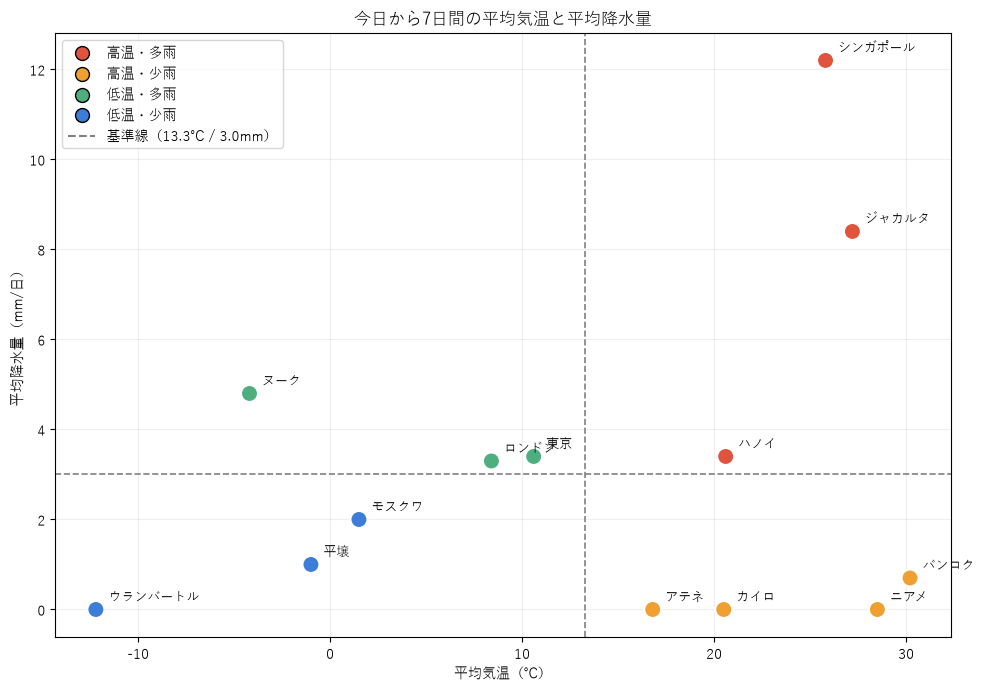

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D

# 日本語フォントの設定（前のセルで設定済みでも、このセル単体で動くように入れています）
candidates = ["Yu Gothic", "Meiryo", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "TakaoGothic"]
installed = {f.name for f in font_manager.fontManager.ttflist}
found = [f for f in candidates if f in installed]
if found:
    plt.rcParams["font.family"] = found[0]
plt.rcParams["axes.unicode_minus"] = False

x = df["平均気温(℃)"]          # 横軸：平均気温
y = df["平均降水量(mm/日)"]    # 縦軸：平均降水量

# ① 点線を引く基準値（デフォルトは13都市の平均値）
temp_line = x.mean()
rain_line = y.mean()
# 自分で決めたい場合は、上の2行を次のように書き換える
# temp_line = 15   # ℃
# rain_line = 3    # mm/日

# ② 点の色を分ける
def pick_color(t, r):
    if t >= temp_line and r >= rain_line:
        return "#e0533d"   # 高温・多雨 → 赤
    if t < temp_line and r < rain_line:
        return "#3b7dd8"   # 低温・少雨 → 青
    if t >= temp_line and r < rain_line:
        return "#f0a030"   # 高温・少雨 → オレンジ
    return "#4caf7d"       # 低温・多雨 → 緑

colors = [pick_color(t, r) for t, r in zip(x, y)]

# ③ 散布図
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(x, y, c=colors, s=150, edgecolors="white", linewidths=1.5, zorder=3)

# 一定ラインの点線
ax.axvline(temp_line, color="gray", linestyle="--", linewidth=1.2, zorder=2)
ax.axhline(rain_line, color="gray", linestyle="--", linewidth=1.2, zorder=2)

# 点の横に都市名を表示
for xi, yi, city in zip(x, y, df["都市"]):
    ax.annotate(city, (xi, yi), textcoords="offset points", xytext=(9, 6), fontsize=9)

# ④ 軸・タイトル・凡例
ax.set_xlabel("平均気温（℃）")
ax.set_ylabel("平均降水量（mm/日）")
ax.set_title("今日から7日間の平均気温と平均降水量")
ax.grid(alpha=0.2)

legend_items = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#e0533d", markersize=10, label="高温・多雨"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#f0a030", markersize=10, label="高温・少雨"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#4caf7d", markersize=10, label="低温・多雨"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#3b7dd8", markersize=10, label="低温・少雨"),
    Line2D([0], [0], color="gray", linestyle="--", label=f"基準線（{temp_line:.1f}℃ / {rain_line:.1f}mm）"),
]
ax.legend(handles=legend_items, loc="best")

plt.tight_layout()
plt.savefig("weather_scatter.png", dpi=150)
plt.show()

## 考察

1. 全体を通して分かったこと
気候区分の異なる都市を比べると、気温と降水量の傾向が都市ごとにはっきり違っていた。例えば、熱帯の都市は気温が高く雨も多い傾向があり、乾燥帯の都市は雨がほとんど降らず、高緯度の都市は気温が低い傾向があった。

2. 気温
気温は、緯度との関係が強いことが分かった。赤道に近い都市ほど高く、高緯度の都市ほど低い。ただし、緯度だけで決まるわけではない。同じ熱帯でも、雨が多い都市より、晴れの日が多い都市のほうが気温が高くなる場合があった。気温は、緯度のほかに天候や季節にも左右されると考えられる。

3. 降水量について
降水量は、気温よりも都市ごとの差が大きかった。また、雪として降る地域でも降水量にカウントされるため、寒い地域でも降水量が多くなることがあった。降水量は「雨」だけでなく「雪」も含む量だという点に注意が必要だと分かった。

4. 気温と降水量
散布図で見ると、「気温が高い＝雨が多い」「気温が低い＝雨が少ない」とは限らなかった。気候を理解するには気温、降水量の両方を組み合わせて見ることが大切だと分かった。

5. 気候区分と実際の天気のずれ
気候区分から予想される天気と、今回のデータが一致しない都市もあった。これは、気候区分が「長い期間の平均的な特徴」を表しているのに対し、今回のデータは「ある1週間の予報」だからだと考えられる。そのため、短い期間のデータだけで、その地域の気候を決めつけることはできないという点に気づけた。

6. データの限界
- 期間が1週間と短く、実行した時期の影響を強く受ける
- 観測値ではなく予報値なので、実際の天気とは異なる場合がある
- 1つの気候区分につき1都市しか調べていないため、その気候区分全体を代表しているとは限らない
- 散布図の基準線は、調べた都市の平均を使っているため、「高い・低い」は調べた都市の中での相対的な比較にすぎない
- 平均値にすると、日ごとの変化や極端な天気が見えにくくなってしまう

7. まとめ
今回の分析で、気候区分ごとの特徴は、気温と降水量のデータからおおまかにつかめることが分かった。一方で、1週間のデータには限界があり、季節や天候によって気候区分のイメージとずれることもあった。
気候をより正確に理解するためには、気温と降水量を一緒に見ること、より長い期間や複数の季節のデータで確かめることが必要だと思った。

## 自分たちで追加した機能や特徴

- 世界13都市の比較：授業の例（1地点）を拡張し、気候区分ごとの代表都市を順に取得
- 平均気温の計算：「最高と最低の平均」よりも実態に近い平均気温で計算した。
- 欠損値（None）の除外とエラー処理：`try / except` で、通信に失敗した都市があっても止まらずに最後まで実行できる。最後に「取得成功 ○ / 13 都市」を表示する
- 降水量の多い順に並べた比較表**：`pandas` で順位つきの表を作成
- 棒グラフと点の複合グラフ：単位の違う降水量と気温を1つのグラフに表示した。
- ※気温は線でつなぐと1つの地域のデータに見えてしまうため、点のみで表現
- 散布図の色分け：気温と降水量の基準線（13都市の平均値）を点線で引き、大体の区分を色分けした

## これから改善したいこと・追加したい機能

- 7日間の日ごとの推移を折れ線グラフにし、都市同士で比べる
- 予報だけでなく、過去のデータ（平年値）と比べて、気候区分の特徴をより確かめる
- 降水量だけでなく、雨・雪の区別や降水確率、天気コード（晴れ・雨・雪など）表示できるようにする
- 基準線を平均値だけでなく、中央値や自分で決めた値に切り替え可能にする
- 結果を地図上に表示し、世界のどこにどんな気候があるかを見やすくする　　　　　　など